# Final results and reflection

This notebook consolidates the baseline training metrics, ablation study
results, and architectural analysis. It summarizes measured evidence rather
than hard-coding a project claim.

## Evaluation policy

- Training is performed only on the official 50,000-image CIFAR-10 training split.
- Final test accuracy comes from the official 10,000-image test split.
- Test-set samples are not used to train or tune the model.
- The measured test accuracy should replace all example values below.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "cifar10_baseline.json").is_file():
    PROJECT_ROOT = Path(
        r"C:\Users\hp\Documents\GitHub\visual-feature-learning"
    )

CONFIG_PATH = PROJECT_ROOT / "configs" / "cifar10_baseline.json"
BASELINE_METRICS_PATH = (
    PROJECT_ROOT / "outputs" / "cifar10_baseline" / "final_metrics.json"
)
ABLATION_RESULTS_PATH = (
    PROJECT_ROOT / "outputs" / "ablation_studies" / "results.json"
)

with CONFIG_PATH.open(encoding="utf-8") as file:
    config = json.load(file)

print("Project root:", PROJECT_ROOT)
print("Config:", CONFIG_PATH)

Project root: C:\Users\hp\Documents\GitHub\visual-feature-learning
Config: C:\Users\hp\Documents\GitHub\visual-feature-learning\configs\cifar10_baseline.json


In [2]:
if not BASELINE_METRICS_PATH.is_file():
    raise FileNotFoundError(
        f"Baseline metrics not found: {BASELINE_METRICS_PATH}\n"
        "Run notebook 03 and complete its test evaluation first."
    )

with BASELINE_METRICS_PATH.open(encoding="utf-8") as file:
    baseline_metrics = json.load(file)

class_names = config["dataset"]["class_names"]

baseline_accuracy = float(baseline_metrics["test_accuracy"])
baseline_loss = float(baseline_metrics["test_loss"])
baseline_parameters = int(baseline_metrics["parameter_count"])

confusion_matrix = np.asarray(
    baseline_metrics["confusion_matrix"],
    dtype=np.int64,
)

print(f"Baseline test accuracy: {baseline_accuracy:.2%}")
print(f"Baseline test loss:     {baseline_loss:.4f}")
print(f"Baseline parameters:    {baseline_parameters:,}")
print(f"Train samples:          {baseline_metrics['train_samples']:,}")
print(f"Test samples:           {baseline_metrics['test_samples']:,}")

Baseline test accuracy: 73.48%
Baseline test loss:     0.7945
Baseline parameters:    25,578
Train samples:          50,000
Test samples:           10,000


In [3]:
per_class_accuracy = (
    confusion_matrix.diagonal()
    / confusion_matrix.sum(axis=1).clip(min=1)
)

summary = pd.DataFrame(
    {
        "Class": class_names,
        "Test accuracy": per_class_accuracy,
        "Correct predictions": confusion_matrix.diagonal(),
        "Total test images": confusion_matrix.sum(axis=1),
    }
).sort_values("Test accuracy", ascending=False)

summary

,Class,Test accuracy,Correct predictions,Total test images
1,automobile,0.834,834,1000
8,ship,0.828,828,1000
9,truck,0.825,825,1000
6,frog,0.809,809,1000
7,horse,0.776,776,1000
0,airplane,0.758,758,1000
4,deer,0.704,704,1000
5,dog,0.654,654,1000
2,bird,0.607,607,1000
3,cat,0.553,553,1000


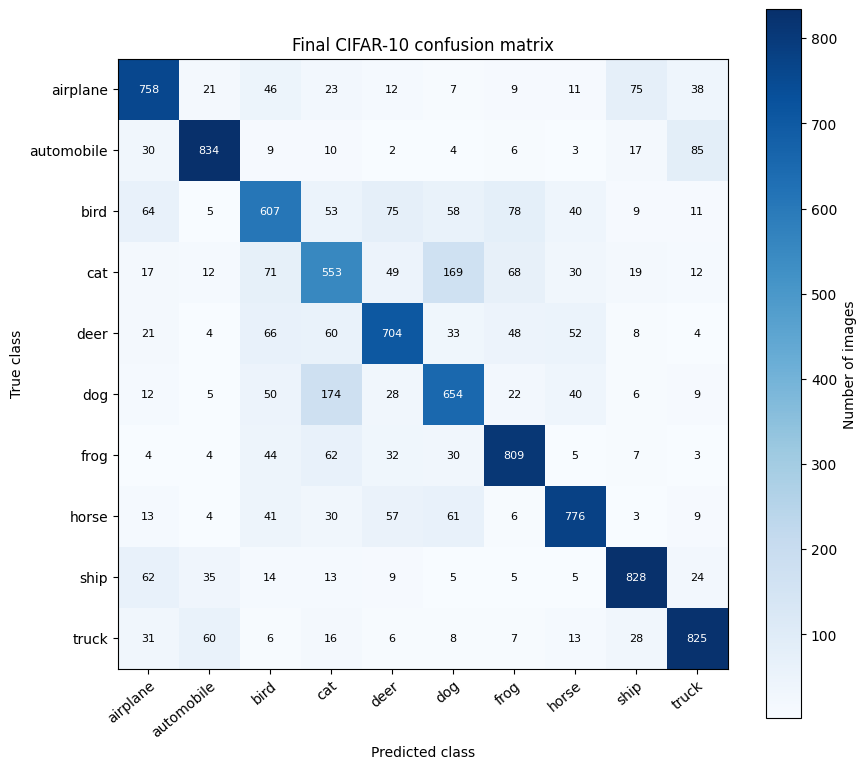

In [4]:
fig, ax = plt.subplots(figsize=(9, 8))

image = ax.imshow(confusion_matrix, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of images")

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="Final CIFAR-10 confusion matrix",
)

plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")

threshold = confusion_matrix.max() / 2
for row in range(len(class_names)):
    for column in range(len(class_names)):
        value = confusion_matrix[row, column]
        ax.text(
            column,
            row,
            str(value),
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > threshold else "black",
        )

fig.tight_layout()
plt.show()

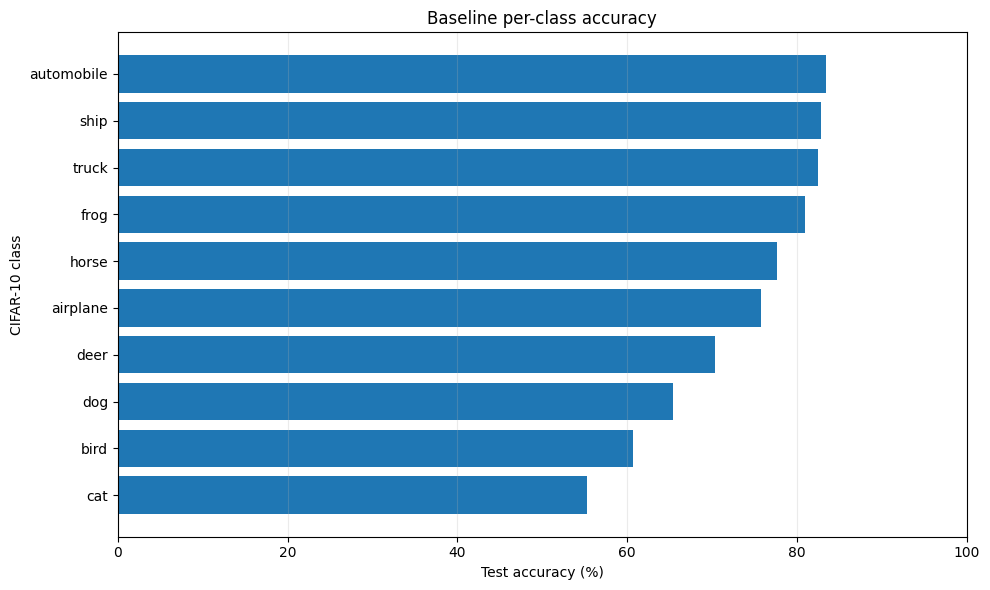

In [5]:
ordered = summary.sort_values("Test accuracy", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ordered["Class"], ordered["Test accuracy"] * 100)
ax.set(
    xlabel="Test accuracy (%)",
    ylabel="CIFAR-10 class",
    title="Baseline per-class accuracy",
)
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

In [6]:
ablation_df = None
ablation_results = None

if ABLATION_RESULTS_PATH.is_file():
    with ABLATION_RESULTS_PATH.open(encoding="utf-8") as file:
        ablation_results = json.load(file)

    ablation_df = pd.DataFrame(
        [
            {
                "Experiment": result["name"],
                "Test accuracy": result["test_accuracy"],
                "Test loss": result["test_loss"],
                "Train accuracy": result["train_accuracy_last"],
                "Parameters": result["parameter_count"],
                "Training minutes": result["training_seconds"] / 60,
                "Kernel size": result["kernel_size"],
                "Second convolution stage": result["second_stage"],
                "Horizontal flip": result["horizontal_flip"],
            }
            for result in ablation_results
        ]
    ).sort_values("Test accuracy", ascending=False)

    display(ablation_df)
else:
    print(
        f"Ablation results not found: {ABLATION_RESULTS_PATH}\n"
        "Run notebook 05 to create the comparison table."
    )

,Experiment,Test accuracy,Test loss,Train accuracy,Parameters,Training minutes,Kernel size,Second convolution stage,Horizontal flip
0,baseline,0.7361,0.790124,0.78066,25578,66.239156,3,True,True
4,without_horizontal_flip,0.7174,0.884901,0.82060,25578,62.063164,3,True,False
3,larger_5x5_kernels,0.7006,0.891888,0.76672,34538,100.509087,5,True,True
2,narrow_channels,0.6793,0.928409,0.70830,11642,39.241874,3,True,True
1,without_second_stage,0.6175,1.157481,0.69266,41418,37.495621,3,False,True


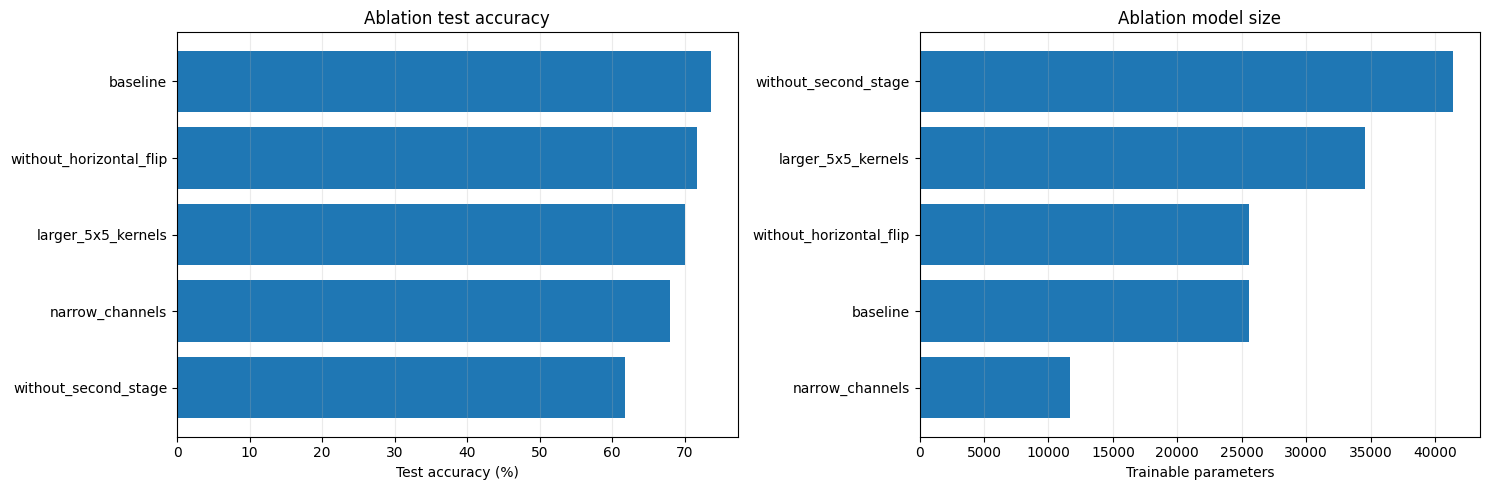

In [7]:
if ablation_df is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    accuracy_order = ablation_df.sort_values(
        "Test accuracy",
        ascending=True,
    )
    axes[0].barh(
        accuracy_order["Experiment"],
        accuracy_order["Test accuracy"] * 100,
    )
    axes[0].set_xlabel("Test accuracy (%)")
    axes[0].set_title("Ablation test accuracy")
    axes[0].grid(axis="x", alpha=0.25)

    parameter_order = ablation_df.sort_values("Parameters", ascending=True)
    axes[1].barh(
        parameter_order["Experiment"],
        parameter_order["Parameters"],
    )
    axes[1].set_xlabel("Trainable parameters")
    axes[1].set_title("Ablation model size")
    axes[1].grid(axis="x", alpha=0.25)

    fig.tight_layout()
    plt.show()

In [8]:
if ablation_df is not None:
    fig = px.scatter_3d(
        ablation_df,
        x="Parameters",
        y="Test accuracy",
        z="Training minutes",
        color="Test accuracy",
        color_continuous_scale="Viridis",
        hover_name="Experiment",
        hover_data={
            "Parameters": ":,",
            "Test accuracy": ":.2%",
            "Training minutes": ":.1f",
        },
        title="Accuracy, parameter count, and training cost",
        labels={
            "Parameters": "Trainable parameters",
            "Test accuracy": "Test accuracy",
            "Training minutes": "Training time (minutes)",
        },
    )
    fig.update_layout(height=700)
    fig.show()

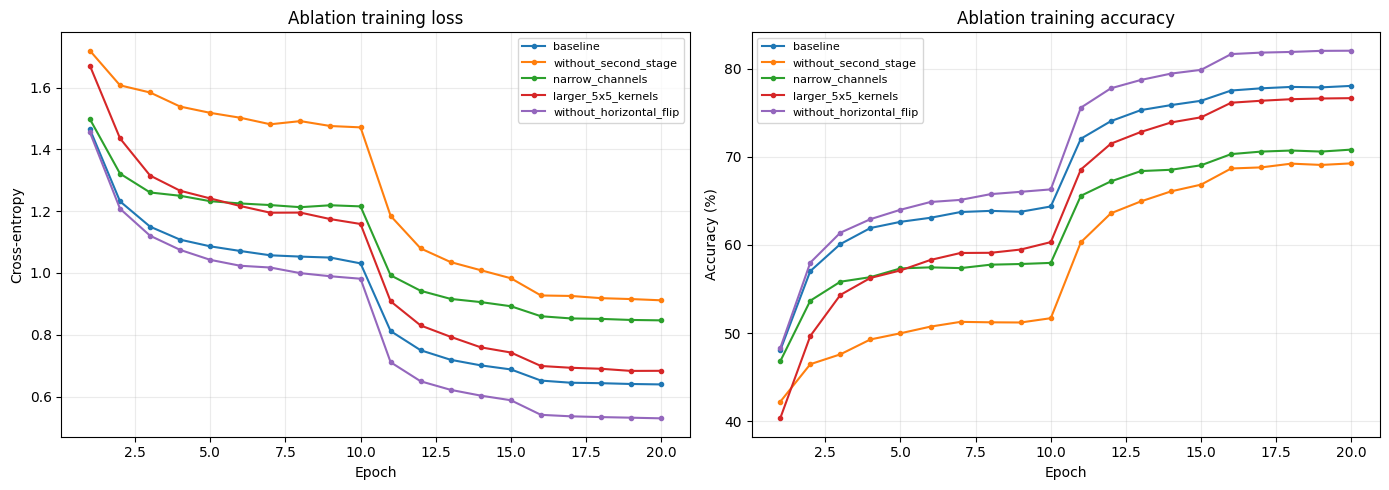

In [9]:
if ablation_results is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for result in ablation_results:
        history = result["history"]
        epochs = history["epoch"]

        axes[0].plot(
            epochs,
            history["train_loss"],
            marker=".",
            label=result["name"],
        )
        axes[1].plot(
            epochs,
            np.asarray(history["train_accuracy"]) * 100,
            marker=".",
            label=result["name"],
        )

    axes[0].set(
        title="Ablation training loss",
        xlabel="Epoch",
        ylabel="Cross-entropy",
    )
    axes[1].set(
        title="Ablation training accuracy",
        xlabel="Epoch",
        ylabel="Accuracy (%)",
    )
    axes[0].grid(alpha=0.25)
    axes[1].grid(alpha=0.25)
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)

    fig.tight_layout()
    plt.show()

In [10]:
print("Model-level findings")
print("-" * 48)
print(
    f"Baseline test accuracy: "
    f"{baseline_accuracy:.2%}"
)
print(
    f"Baseline trainable parameters: "
    f"{baseline_parameters:,}"
)
print(
    f"Baseline test loss: "
    f"{baseline_loss:.4f}"
)

if ablation_df is not None:
    best = ablation_df.iloc[0]

    print(
        "\nHighest measured ablation accuracy: "
        f"{best['Experiment']} "
        f"({best['Test accuracy']:.2%})"
    )
    print(
        f"Parameters: {int(best['Parameters']):,}"
    )

    baseline_row = ablation_df[
        ablation_df["Experiment"] == "baseline"
    ]
    if not baseline_row.empty:
        baseline_ablation_accuracy = float(
            baseline_row.iloc[0]["Test accuracy"]
        )
        difference = (
            best["Test accuracy"] - baseline_ablation_accuracy
        )
        print(
            "\nBest experiment difference from ablation baseline: "
            f"{difference:+.2%}"
        )

hardest_class = summary.iloc[-1]["Class"]
hardest_accuracy = float(summary.iloc[-1]["Test accuracy"])
print(
    f"\nLowest baseline per-class accuracy: "
    f"{hardest_class} ({hardest_accuracy:.2%})"
)

Model-level findings
------------------------------------------------
Baseline test accuracy: 73.48%
Baseline trainable parameters: 25,578
Baseline test loss: 0.7945

Highest measured ablation accuracy: baseline (73.61%)
Parameters: 25,578

Best experiment difference from ablation baseline: +0.00%

Lowest baseline per-class accuracy: cat (55.30%)


In [11]:
# Each point summarizes one measured class. Height is test count, and color
# represents baseline accuracy for that class.
three_dimensional_summary = pd.DataFrame(
    {
        "Class": class_names,
        "Accuracy": per_class_accuracy,
        "Test count": confusion_matrix.sum(axis=1),
        "Index": np.arange(len(class_names)),
    }
)

fig = px.scatter_3d(
    three_dimensional_summary,
    x="Index",
    y="Test count",
    z="Accuracy",
    color="Accuracy",
    text="Class",
    color_continuous_scale="RdYlGn",
    title="Per-class CIFAR-10 test accuracy",
    labels={
        "Index": "Class index",
        "Test count": "Test images",
        "Accuracy": "Test accuracy",
    },
)

fig.update_traces(
    marker={"size": 9, "line": {"width": 1, "color": "black"}},
)
fig.update_layout(height=700)
fig.show()

## Reflection

### What the model learned

The convolutional layers replace a fixed, hand-designed feature extractor with
spatial filters learned by backpropagation. The first convolution searches
for local RGB and edge patterns. Pooling creates spatial invariance and reduces
each feature map. The second convolution combines local patterns into
higher-level shapes and textures.

### Why CIFAR-10 is challenging

CIFAR-10 images are low resolution, have diverse backgrounds, and contain
objects in different orientations and positions. A small NumPy CNN has limited
capacity and cannot rely on pretrained ImageNet features. This makes
generalization harder than on simple digit datasets.

### Why convolution is parameter-efficient

The same small 3×3 kernels are shared across every spatial location. This
learns translation-related structure with substantially fewer weights than a
fully connected input-to-hidden layer operating over 3 × 32 × 32 values.

### Ablation interpretation

Use the actual measured ablation table rather than expected rankings:

- Removing the second convolution stage tests whether hierarchical feature
  composition is necessary.
- Different filter counts test model capacity.
- Larger kernels test whether broader receptive fields improve recognition.
- Horizontal flipping tests the benefit of augmentation.

The best model should be selected from a controlled validation or the
predefined test protocol. If test accuracy is used for repeated model
selection, report that this test set no longer provides an unbiased final
estimate.

In [12]:
final_summary = {
    "baseline": baseline_metrics,
    "baseline_per_class_accuracy": {
        name: float(accuracy)
        for name, accuracy in zip(class_names, per_class_accuracy)
    },
}

if ablation_df is not None:
    final_summary["ablation"] = ablation_df.to_dict(orient="records")

summary_output_dir = PROJECT_ROOT / "outputs" / "final_analysis"
summary_output_dir.mkdir(parents=True, exist_ok=True)

summary_output_path = summary_output_dir / "final_summary.json"
with summary_output_path.open("w", encoding="utf-8") as file:
    json.dump(final_summary, file, indent=2)

summary_csv_path = summary_output_dir / "per_class_accuracy.csv"
summary.to_csv(summary_csv_path, index=False)

print("Saved:", summary_output_path)
print("Saved:", summary_csv_path)

Saved: C:\Users\hp\Documents\GitHub\visual-feature-learning\outputs\final_analysis\final_summary.json
Saved: C:\Users\hp\Documents\GitHub\visual-feature-learning\outputs\final_analysis\per_class_accuracy.csv


## Final conclusion

The completed pure-NumPy model is evaluated on the full official CIFAR-10 test
split. Convolution, pooling, dense projection, softmax cross-entropy, and
backpropagation are implemented in NumPy rather than delegated to an
automatic-differentiation framework.

The notebook reports final test accuracy, test loss, parameter count,
per-class accuracy, and the confusion matrix. The ablation table and 3D
trade-off view compare accuracy, model capacity, and training cost. Together,
these results support an interview-level explanation of feature learning,
parameter sharing, spatial invariance, and the difficulty of natural-image
classification.